# 04 - ANN leave-one-day-out cross-validation (10 days)

Features : max over usable channels, then log10 (100 values per 10 second window).
Each fold: 1 test day, the next day as valisation (early stopping only), the remaining 8 days for training.
The scaler and pos-weight are fitted on training days only.

In [8]:
import sys, importlib, time 
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py, torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, 
                             confusion_matrix, ConfusionMatrixDisplay, 
                             classification_report)

PROJECT_ROOT=Path.cwd()
if PROJECT_ROOT.name=="notebooks":
    PROJECT_ROOT=PROJECT_ROOT.parent

sys.path.append(str(PROJECT_ROOT/"src"))

import data_loader,models,training,evaluation
for m in (data_loader,models,training,evaluation):
    importlib.reload(m)
from data_loader import create_binary_label
from models import ANNModel
from training import train_model
from evaluation import predict_model

Data_path=r"C:/Users/urvi_/Downloads/dataset.h5"
RESULTS =PROJECT_ROOT / "results"
figs=RESULTS/"figures"
figs.mkdir(parents=True,exist_ok=True)
cache=RESULTS/"features_all_days.npz"

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device",device)

Device cuda


In [9]:
def build_feature_cache(data_path, out_path, chunk=1000, bad=(59,60,61)):
    with h5py.File(data_path,"r")as f:
        n,n_ch,n_bands=f["X"].shape
        keep=[c for c in range(n_ch) if c not in bad]
        feats=np.empty((n,n_bands),dtype=np.float32)
        for s in range(0,n,chunk):
            block=f["X"][s:s+chunk][:,keep,:]
            feats[s:s+chunk]=np.log10(block.max(axis=1)+1e-20)
            print(f"{min(s+chunk,n)}/{n}",end="\r")
        y=f["y"][:]
        dt=np.array([d.decode() if isinstance(d,bytes) else str(d) for d in f["datetimes"][:]])
    np.savez(out_path,X=feats,y=y,dt=dt)
    
if not cache.exists():
    t0=time.time()
    build_feature_cache(Data_path,cache)
    print("\n Build cache in", round(time.time()-t0),"seconds")
else:
    print("Cache already exists:",cache)

Cache already exists: c:\Users\urvi_\OneDrive - Adelaide University\Desktop\Sem2\ProgAIML2\Vessel_Detection_DAS\results\features_all_days.npz


In [10]:
d=np.load(cache)
x_all=d["X"]
y_dist=d["y"]
y_all=create_binary_label(y_dist,threshold=1000)
day_of=np.array(pd.to_datetime(d["dt"]).date)
days_sorted=sorted(set(day_of))

print(x_all.shape,y_all.shape)
print("Days: ",len(days_sorted),days_sorted[0],"to",days_sorted[-1])

(74771, 100) (74771,)
Days:  10 2023-06-16 to 2023-06-25


In [11]:
overview=pd.DataFrame({
    "day":[str(x) for x in days_sorted],
    "windows":[int((day_of==x).sum()) for x in days_sorted],
    "near_pct":[round(100*y_all[day_of==x].mean(),1) for x in days_sorted],
})
print(overview)
overview.to_csv(RESULTS/"daily_overview.csv", index=False)

          day  windows   near_pct
0  2023-06-16     7898  35.799999
1  2023-06-17     8616  32.500000
2  2023-06-18     8616  31.799999
3  2023-06-19     8616  30.100000
4  2023-06-20     8616  36.500000
5  2023-06-21     7577  26.900000
6  2023-06-22     2464  39.599998
7  2023-06-23     8616  34.099998
8  2023-06-24     8616  35.000000
9  2023-06-25     5136  23.200001


In [12]:
from typing import Any


class VesselDetection(Dataset):
    def __init__(self,X,y):
        self.X=torch.tensor(X,dtype=torch.float32)
        self.y=torch.tensor(y,dtype=torch.float32)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.X[i],self.y[i]

In [13]:
def run_fold(test_day,epoch=100,lr=1e-3, batch=64, dropout=0.3,wd=1e-4,seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
    
    i=days_sorted.index(test_day)
    val_day=days_sorted[(i+1)%len(days_sorted)]
    
    test_idx=np.where(day_of==test_day)[0]
    val_idx=np.where(day_of==val_day)[0]
    fit_idx=np.where((day_of!=test_day)&(day_of!=val_day))[0]
    
    ss=StandardScaler().fit(x_all[fit_idx])
    
    def make_loader(idx,shuffle):
        ds=VesselDetection(ss.transform(x_all[idx]),y_all[idx])
        return DataLoader(ds,batch_size=batch,shuffle=shuffle)
    
    train_loader=make_loader(fit_idx,True)
    val_loader=make_loader(val_idx,False)
    test_loader=make_loader(test_idx,False)
    
    n_far=(y_all[fit_idx]==0).sum()
    n_near=(y_all[fit_idx]==1).sum()
    criterion=nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_far/n_near],dtype=torch.float32).to(device))
    
    model=ANNModel(input_size=x_all.shape[1],hidden1=256,hidden2=128,dropout=dropout).to(device)
    optimizer=torch.optim.Adam(model.parameters(),lr=lr,weight_decay=wd)
    
    history=train_model(model,train_loader,criterion,optimizer,device,
                        epochs=epoch,val_loader=val_loader,patience=10)
    
    y_true,y_pred,y_prob=predict_model(model,test_loader,device)
    y_true=y_true.astype(int)
    y_pred=y_pred.astype(int).flatten()
    y_prob=y_prob.flatten()
    far_f1,near_f1=f1_score(y_true,y_pred,average=None,zero_division=0)
    
    metrics={
        "test_day":str(test_day),
        "val_day":str(val_day),
        "n_train":len(fit_idx),
        "n_val":len(val_idx),
        "n_test":len(test_idx),
        "best_epoch":int(np.argmin(history["val_loss"]))+1,
        "epochs_run":len(history["train_loss"]),
        "accuracy":accuracy_score(y_true,y_pred),
        "weighted_f1":f1_score(y_true,y_pred,average="weighted",zero_division=0),
        "far_f1":far_f1,
        "near_f1":near_f1,
        "auc":roc_auc_score(y_true,y_prob)
    }
    
    return metrics,history,(y_true,y_pred,y_prob)

In [14]:
results,histories,pooled=[],{},[]
t_all=time.time()

for day in days_sorted:
    t0=time.time()
    print(f"\n === Test day {day} ===")
    r,h,preds=run_fold(day)
    results.append(r)
    histories[str(day)]=h
    pooled.append((str(day),*preds))
    pd.DataFrame(results).to_csv(RESULTS/"ann_10day_partial.csv",index=False)
    print({k:(round(v,4) if isinstance(v,float) else v)for k,v in r.items()})
    print(f"Fold time: {round(time.time()-t0)}s")
    
print("\n Total time (min):", round((time.time()-t_all)/60,1))



 === Test day 2023-06-16 ===
Epoch 1/100 | Train loss: 0.4486 | Val loss: 0.4289
Epoch 2/100 | Train loss: 0.4037 | Val loss: 0.4071
Epoch 3/100 | Train loss: 0.3848 | Val loss: 0.4164
Epoch 4/100 | Train loss: 0.3742 | Val loss: 0.3952
Epoch 5/100 | Train loss: 0.3606 | Val loss: 0.4010
Epoch 6/100 | Train loss: 0.3520 | Val loss: 0.3993
Epoch 7/100 | Train loss: 0.3423 | Val loss: 0.4023
Epoch 8/100 | Train loss: 0.3338 | Val loss: 0.4195
Epoch 9/100 | Train loss: 0.3293 | Val loss: 0.4043
Epoch 10/100 | Train loss: 0.3203 | Val loss: 0.3935
Epoch 11/100 | Train loss: 0.3160 | Val loss: 0.4203
Epoch 12/100 | Train loss: 0.3101 | Val loss: 0.4033
Epoch 13/100 | Train loss: 0.3063 | Val loss: 0.4158
Epoch 14/100 | Train loss: 0.3010 | Val loss: 0.4362
Epoch 15/100 | Train loss: 0.2957 | Val loss: 0.4168
Epoch 16/100 | Train loss: 0.2914 | Val loss: 0.4171
Epoch 17/100 | Train loss: 0.2877 | Val loss: 0.4303
Epoch 18/100 | Train loss: 0.2824 | Val loss: 0.4274
Epoch 19/100 | Train loss

In [16]:
df=pd.DataFrame(results)
metric_cols=["accuracy","weighted_f1","far_f1","near_f1","auc"]

print(df[["test_day","val_day","n_test","best_epoch","epochs_run"]+metric_cols].round(4))
summary=df[metric_cols].agg(["mean","std"]).round(4)
print("\n", summary)

df["model"]="ANN"
df["split"]="leave_one_day_out_10days"
df.to_csv(RESULTS/"tables"/"ann_10day_results.csv",index=False)
summary.to_csv(RESULTS/"tables"/"ann_10day_summary.csv")

     test_day     val_day  n_test  best_epoch  epochs_run  accuracy  \
0  2023-06-16  2023-06-17    7898          10          20    0.8630   
1  2023-06-17  2023-06-18    8616           3          13    0.9029   
2  2023-06-18  2023-06-19    8616           4          14    0.8578   
3  2023-06-19  2023-06-20    8616           6          16    0.8794   
4  2023-06-20  2023-06-21    8616           2          12    0.8702   
5  2023-06-21  2023-06-22    7577           1          11    0.9083   
6  2023-06-22  2023-06-23    2464           3          13    0.7829   
7  2023-06-23  2023-06-24    8616           2          12    0.8774   
8  2023-06-24  2023-06-25    8616           6          16    0.8889   
9  2023-06-25  2023-06-16    5136           1          11    0.9272   

   weighted_f1  far_f1  near_f1     auc  
0       0.8640  0.8911   0.8152  0.9312  
1       0.9023  0.9288   0.8472  0.9442  
2       0.8609  0.8905   0.7972  0.9415  
3       0.8777  0.9154   0.7901  0.9064  
4       

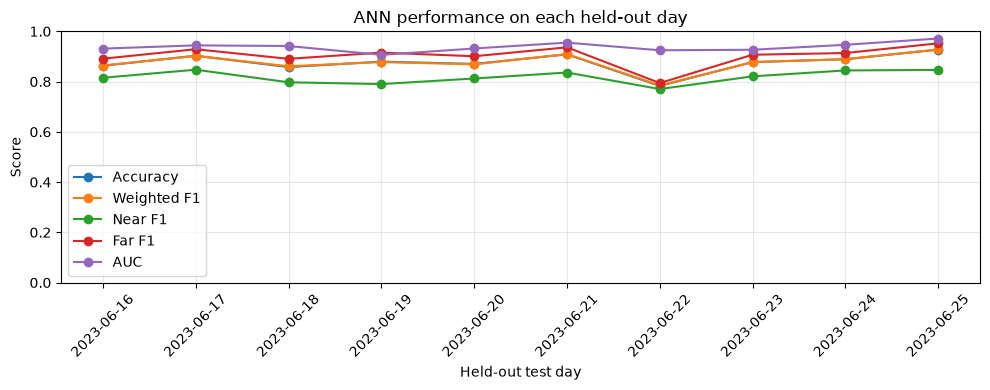

In [18]:
plt.figure(figsize=(10,4))
for col,lab in [("accuracy","Accuracy"),("weighted_f1","Weighted F1"),
                ("near_f1","Near F1"),("far_f1","Far F1"),("auc","AUC")]:
    plt.plot(df["test_day"],df[col],marker="o",label=lab)
plt.xticks(rotation=45)
plt.ylim(0,1)
plt.xlabel("Held-out test day")
plt.ylabel("Score")
plt.title("ANN performance on each held-out day")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figs/"ann_10day_per_fold.png",dpi=300,bbox_inches="tight")
plt.show()

[[45648  4873]
 [ 4045 20205]]
               precision    recall  f1-score   support

Far (>=1000m)     0.9186    0.9035    0.9110     50521
Near (<1000m)     0.8057    0.8332    0.8192     24250

     accuracy                         0.8807     74771
    macro avg     0.8621    0.8684    0.8651     74771
 weighted avg     0.8820    0.8807    0.8812     74771



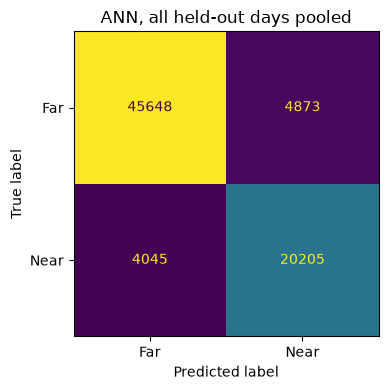

In [21]:
yt=np.concatenate([p[1] for p in pooled])
yp=np.concatenate([p[2] for p in pooled])
pr=np.concatenate([p[3] for p in pooled])
days_col=np.concatenate([[p[0]]*len(p[1]) for p in pooled])

cm=confusion_matrix(yt,yp)
print(cm)
print(classification_report(yt,yp,target_names=["Far (>=1000m)","Near (<1000m)"],digits=4))

fig,ax=plt.subplots(figsize=(5,4))
ConfusionMatrixDisplay(cm,display_labels=["Far","Near"]).plot(ax=ax,colorbar=False,values_format="d")
ax.set_title("ANN, all held-out days pooled")
plt.tight_layout()
plt.savefig(figs/"ann_10day_confusion_matric.png",dpi=300,bbox_inches="tight")
plt.show()

pd.DataFrame({"test_day":days_col,"true":yt,"pred":yp,"prob":pr}).to_csv(RESULTS/"tables"/"ann_10day_predictions.csv",index=False)


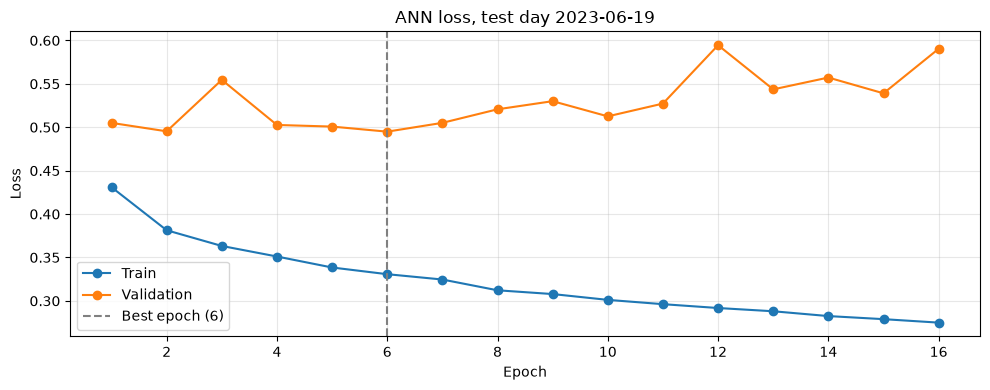

In [20]:
day="2023-06-19"
h=histories[day]
n=len(h["train_loss"])
best=int(np.argmin(h["val_loss"]))+1

plt.figure(figsize=(10,4))
plt.plot(range(1,n+1),h["train_loss"],marker="o",label="Train")
plt.plot(range(1,n+1),h["val_loss"],marker="o",label="Validation")
plt.axvline(best,linestyle="--",color="gray",label=f"Best epoch ({best})")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"ANN loss, test day {day}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figs/"ann_10day_loss_example.png", dpi=300, bbox_inches="tight")
plt.show()